In [1]:
import cv2
img=cv2.imread("/content/Clean Blue TechSolutions Invoice.png")
# through open cv we can read the image in the matrix form

In [2]:
if img is None:
  print("image not loaded")
else:
  print("image loaded")

image not loaded


In [ ]:
print(img.size)

4717494


In [ ]:
print(img.shape)

(1194, 1317, 3)


In [ ]:
B,G,R=cv2.split(img)    #   colour channnel      to chek in evry pixcel is this is prsent or not
print(B.shape)
print(G.shape)
print(R.shape)

(1194, 1317)
(1194, 1317)
(1194, 1317)


In [6]:
gray=cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
print(gray.shape)
# Grayscale
# Grayscale is an image with only one intensity value for each pixel.
# Pixel values range from 0 (black) to 255 (white).
# A color image has 3 channels: Blue, Green, and Red.
# A grayscale image has only 1 channel.
# We use grayscale in OCR to remove color information.
# It helps focus on the difference between text and background.
# It also makes further preprocessing like thresholding easier.
# Color image → (Height, Width, 3)
# Grayscale image → (Height, Width)

error: OpenCV(5.0.0) /io/opencv/modules/imgproc/src/color.cpp:199: error: (-215:Assertion failed) !_src.empty() in function 'cvtColor'


In [ ]:
resized=cv2.resize(gray,(600,600))
print(resized.shape)
#Resizing means changing the width and height of an image.
# Make very large images smaller → faster processing
# Make very small text larger → sometimes easier for OCR
# Keep document images at a consistent size when needed
# Reduce unnecessary computational cost

(600, 600)


In [ ]:
_, thresh = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)
# Thresholding
# Thresholding converts a grayscale image into black and white based on a threshold value.
# Pixels below the threshold are converted to black.
# Pixels above the threshold are converted to white.
# It helps separate text from the background.
# It can improve OCR when the text and background are clearly distinguishable.
# Common methods: Binary, Adaptive, and Otsu Thresholding.


In [ ]:
# Gaussian Blur
clean = cv2.GaussianBlur(gray, (3, 3), 0)
# Noise Removal
# Noise means unwanted pixels or distortions that can affect OCR.
# We can use filters such as Median Blur and Gaussian Blur to reduce noise.
# Median Blur examines a small neighborhood around each pixel.
# In cv2.medianBlur(gray, 3), 3 means a 3 × 3 neighborhood is used.
# A 3 × 3 neighborhood contains 9 pixels.
# The center pixel is replaced using the median value of these pixels.
# This helps remove small isolated noise while preserving edges.
# Noise removal can make text clearer for OCR.

In [ ]:
#Image Enhancement
# It can make faint text more visible.
# It can improve contrast between text and background.
# It can make blurry text more distinguishable.
# It may improve OCR accuracy on difficult images.


In [ ]:
# now --------------------Tesseract---------------------------------------
# Tesseract is an OCR engine.
# It analyzes an image and recognizes the text present in that image.
# It converts text from an image into machine-readable text.
# Tesseract itself is written in C++.
# Python can use Tesseract through the pytesseract library.

In [ ]:
#pytesseract
# pytesseract is a Python wrapper for Tesseract.
# It allows Python programs to communicate with the Tesseract OCR engine.
# We use pytesseract to send an image to Tesseract and receive the recognized text.

In [ ]:
# Document Image           # Tesseract → actual OCR engine
                           # pytesseract → Python interface used to access Tesseract
#       ↓
# OpenCV preprocessing
#       ↓
# pytesseract
#       ↓
# Tesseract OCR Engine
#       ↓
# Extracted Text

In [4]:
!sudo apt-get update
!sudo apt-get install -y tesseract-ocr
!pip install pytesseract

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease [1,578 B]
Get:3 https://cli.github.com/packages stable/main amd64 Packages [357 B]
Get:4 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  Packages [1,992 kB]
Get:5 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:6 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Hit:7 http://archive.ubuntu.com/ubuntu noble InRelease
Get:8 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:9 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:10 http://security.ubuntu.com/ubuntu noble-security/universe amd64 Packages [1,550 kB]
Get:11 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [3,089 kB]
Get:12 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:13 http://archive.ubuntu.com/ubuntu noble-updates/ma

In [7]:
import pytesseract



In [ ]:
text=pytesseract.image_to_string(gray)

In [ ]:
# OCR Configuration
# OCR configuration means the settings we give to Tesseract
# to control how it processes and recognizes text from an image.
# Different documents may require different configurations.
# Configuration can control things like:
# 1. Page layout
# 2. Language
# 3. OCR engine mode
# 4. Character restrictions
# 5. Whitespace and output behavior

In [ ]:
# PSM
# PSM = Page Segmentation Mode.
# It tells Tesseract how the text is arranged in the image.

# Language
# Tells Tesseract which language to recognize.
# Example: English → eng

# OEM
# OEM = OCR Engine Mode.
# It controls which OCR engine mode Tesseract uses.

# Character whitelist
# Restricts recognition to specific characters.
# Useful when you know the expected characters.
# Example: numbers only → 0123456789

In [ ]:
# PSM 3
# Automatic page segmentation.
# Tesseract automatically tries to understand the page layout.
# This is the default mode.

# PSM 6
# Assume a single uniform block of text.
# Useful when your image contains one main block of text.

# PSM 7
# Treat the image as a single text line.
# Useful for things like:
# "Invoice Number: INV-1023"

# PSM 8
# Treat the image as a single word.
# Useful when extracting one isolated word.

# PSM 10
# Treat the image as a single character.
# Useful when the image contains only one character.

In [ ]:
# PSM 3 - Automatic page segmentation
text_3 = pytesseract.image_to_string(gray, config="--psm 3")

# PSM 6 - Single uniform block of text
text_6 = pytesseract.image_to_string(gray, config="--psm 6")

# PSM 7 - Single text line
text_7 = pytesseract.image_to_string(gray, config="--psm 7")

# PSM 8 - Single word
text_8 = pytesseract.image_to_string(gray, config="--psm 8")
#PSM 10 - single character
text_10=pytesseract.image_to_string(gray, config="--psm 10")

print("----- PSM 3 -----")
print(text_3)

print("----- PSM 6 -----")
print(text_6)

print("----- PSM 7 -----")
print(text_7)

print("----- PSM 8 -----")
print(text_8)

print("----- PSM 10 -----")
print(text_10)



----- PSM 3 -----
TechSolutions

eqmnwem Better Technology. A Brighter Future.

TechSolutions Pvt. Ltd.

123 Business Park, Green Road
Bengaluru, Karnataka - 560001
Phone: +91 98765 43210

Email: support@techsolutions.in
Website: www.techsolutions.in

INVOICE

Bill To:

Adarsh Bhardwaj
Siddaganga Institute of Technology
Bhagalpur, Bihar - 813210

India
# Description
1 Laptop Stand
2 Wireless Mouse
3 USB-C Cable (1.5m)
4 Laptop Sleeve

Payment Details:

BankName —: HDFC Bank
AccountNo — : 50100234567890
IFSC Code : HDFC0001234

Terms & Conditions:

1. Payment is due within 14 days from the invoice date.
2. Goods once sold will not be taken back or exchanged.
3. For any queries, please contact us at support@techsolutions.in

Invoice No: TS-2026-0457
Invoice Date: 15 Oct 2026
Due Date: 29 Oct 2026
Quantity Unit Price (%) Total (%)
1 1,499.00 1,499.00
1 799.00 799.00
2 499.00 499.00
1 999.00 999.00
Sub Total 3,796.00
Discount (5%) -189.80
Total Amount X 3,606.20

Thank you for your busines

In [ ]:
# Topic 4: Bounding Boxes in OCR

## 1. What Is a Bounding Box?

#- A bounding box is a rectangular box drawn around a word or text region in an image.
# It tells us the location of recognized text in an image.
#- OCR recognizes text, while bounding boxes provide the location of that text.

### Example

#- Name: Adarsh Bhardwaj
#- Invoice No: TS-2026-0457
#- Total Amount: ‣3,606.20
#- OCR recognizes the text.
#- Bounding boxes identify where the words appear in the invoice.

## 2. Why Do We Use Bounding Boxes?

#- To locate words in an image.
#- To draw rectangles around recognized text.
#- To inspect whether OCR detected the correct text regions.
#- To locate important fields in invoices, resumes, ID cards and forms.
#- To help with document layout analysis and field extraction.
#- **Important:** Bounding boxes identify text locations. They do not automatically understand the meaning of the text.

## 3. What Is `image_to_string()`?

#- `pytesseract.image_to_string()` extracts recognized text from an image.
#- It returns the recognized text as a string.
#- It does not return bounding-box coordinates or confidence scores.

### Example

#```python
#text = pytesseract.image_to_string(image)
#print(text)
#```

### Possible Output

#```text
#Invoice No: TS-2026-0457
#Name: Adarsh Bhardwaj
#Total Amount: 3606.20
#```

#- **Use:** When we mainly need to read the text in an image.

## 4. What Is `image_to_data()`?

#- `pytesseract.image_to_data()` returns structured OCR information.
#- With `output_type=Output.DICT`, the result is a dictionary.
#- It provides recognized text, coordinates, dimensions and confidence scores.

### Example

#```python
from pytesseract import Output

data = pytesseract.image_to_data(
    img,
    output_type=Output.DICT
)

#print(data.keys())
#```

### Important Fields

#- `text`: Recognized text.
#- `left`: Distance from the left edge of the image.
#- `top`: Distance from the top edge of the image.
#- `width`: Width of the bounding box.
#- `height`: Height of the bounding box.
#- `conf`: OCR confidence score.
#- `level`: Level of the text structure, such as page, block, line or word.

## 5. Difference Between `image_to_string()` and `image_to_data()`

#| Feature | `image_to_string()` | `image_to_data()` |
#|---|---|---|
#| Extract recognized text | Yes | Yes |
#| Output format | String | Dictionary with `Output.DICT` |
#| Word coordinates | No | Yes |
#| Bounding-box dimensions | No | Yes |
#| Confidence scores | No | Yes |
#| Main purpose | Read text | Read and locate text |

#- `image_to_string()` = What text was recognized?
#- `image_to_data()` = What text was recognized, where is it located, and what confidence score was assigned?

## 6. Understanding Bounding-Box Coordinates

#- `left` or x-coordinate: Distance from the left edge.
#- `top` or y-coordinate: Distance from the top edge.
#- `width`: Horizontal size of the box.
#- `height`: Vertical size of the box.

### Image Coordinate System

#- The origin `(0, 0)` is normally at the top-left corner.
#- The x-coordinate increases toward the right.
#- The y-coordinate increases downward.

### Example

#```python
{
    "left": 100,
    "top": 50,
    "width": 80,
    "height": 25,
    "conf": 92,
    "text": "Adarsh"
}
#```

#- Text: `Adarsh`
#- Left: 100 pixels.
#- Top: 50 pixels.
#- Width: 80 pixels.
#- Height: 25 pixels.
#- Confidence: 92.
#- These are example values, not actual OCR results.

## 7. Extracting Text and Coordinates

# We populate 'data' using the actual OCR values obtained from pytesseract
data = pytesseract.image_to_data(
    img,
    output_type=Output.DICT
)

for i in range(len(data["text"])):
    word = data["text"][i]
    if isinstance(word, str) and word.strip():
        print(
            word,
            data["left"][i],
            data["top"][i],
            data["width"][i],
            data["height"][i],
            data["conf"][i]
        )
        cv2.rectangle(
            img,
            (data["left"][i], data["top"][i]),
            (data["left"][i] + data["width"][i], data["top"][i] + data["height"][i]),
            (0, 255, 0),
            2
        )
#```

#- This prints each non-empty text entry with its coordinates, dimensions and confidence score.
#- The returned data can include entries for different text levels, not only individual words.

## 8. What Is OCR Confidence?

#- Confidence is a score indicating how confident Tesseract is in its recognition of a text entry.
#- A higher score generally indicates greater recognition confidence.
#- A lower score can indicate potentially unreliable recognition.
#- A confidence value of `-1` commonly occurs for non-word-level entries.
#- **Important:** A high confidence score does not guarantee that the text is correct.

## 9. How Do Bounding Boxes Help My AI Document System?

#- Step 1: Input a document image.
#- Step 2: CNN classifies the document type.
#- Step 3: Tesseract recognizes the text.
#- Step 4: `image_to_data()` provides text positions and confidence scores.
#- Step 5: Regex rules extract fields such as dates, email addresses, IDs and amounts.
#- Step 6: Human review handles missing or suspicious results.
#- Bounding boxes help locate and inspect text.
#- Regex or other extraction logic is still needed to identify which text represents a name, date or total amount.

## 10. Final Summary

#- OCR converts text in images into machine-readable text.
##- `image_to_data()` provides structured text information, coordinates and confidence scores.
#- Bounding boxes identify the location and dimensions of recognized text.
#- Confidence scores help identify potentially unreliable OCR results.
#- Bounding boxes alone do not understand the meaning of a field.

TechSolutions 186 50 379 46 92
eum 43 122 119 13 0
Better 192 115 68 17 81
Technology. 267 113 132 24 96
A 408 115 15 17 96
Brighter 433 113 89 24 96
Future. 531 115 74 17 96
TechSolutions 933 29 144 17 92
Pvt. 1086 30 36 16 96
Ltd. 1131 29 35 17 96
123 934 59 32 14 96
Business 974 58 83 15 96
Park, 1065 57 46 19 96
Green 1119 58 56 15 96
Road 1183 57 46 16 96
Bengaluru, 934 85 100 21 96
Karnataka 1042 85 92 16 93
- 1142 94 6 2 93
560001 1155 87 64 14 96
Phone: 935 119 63 16 96
+91 1007 121 31 14 96
98765 1045 121 54 14 96
43210 1105 121 53 14 96
Email: 935 147 56 16 93
support@techsolutions.in 1000 147 233 21 91
Website: 933 175 79 16 93
www.techsolutions.in 1020 175 192 16 90
INVOICE 49 247 221 44 95
Bill 48 333 32 17 96
To: 87 334 30 16 96
Adarsh 47 373 79 19 96
Bhardwaj 136 373 105 24 96
Siddaganga 47 408 123 24 92
Institute 179 409 86 18 96
of 273 408 21 19 96
Technology 299 409 123 23 96
Bhagalpur, 48 442 107 24 92
Bihar 164 442 52 18 93
- 223 452 7 3 92
813210 237 444 71 16 96
I

In [ ]:
text = pytesseract.image_to_string(img)
print(text)


TechSolutions

eum Better Technology. A Brighter Future.

TechSolutions Pvt. Ltd.

123 Business Park, Green Road
Bengaluru, Karnataka - 560001
Phone: +91 98765 43210

Email: support@techsolutions.in
Website: www.techsolutions.in

INVOICE

Bill To:

Adarsh Bhardwaj
Siddaganga Institute of Technology
Bhagalpur, Bihar - 813210

India
# Description
1 Laptop Stand
2 Wireless Mouse
3 USB-C Cable (1.5m)
4 Laptop Sleeve

Payment Details:

BankName —: HDFC Bank
AccountNo — : 50100234567890
IFSC Code : HDFC0001234

Terms & Conditions:

1. Payment is due within 14 days from the invoice date.
2. Goods once sold will not be taken back or exchanged.
3. For any queries, please contact us at support@techsolutions.in

Invoice No: TS-2026-0457
Invoice Date: 15 Oct 2026
Due Date: 29 Oct 2026
Quantity Unit Price (%) Total (%)
1 1,499.00 1,499.00
1 799.00 799.00
2 499.00 499.00
1 999.00 999.00
Sub Total 3,796.00
Discount (5%) -189.80
Total Amount ® 3,606.20

Thank you for your business!
TechSolutions Pvt. 

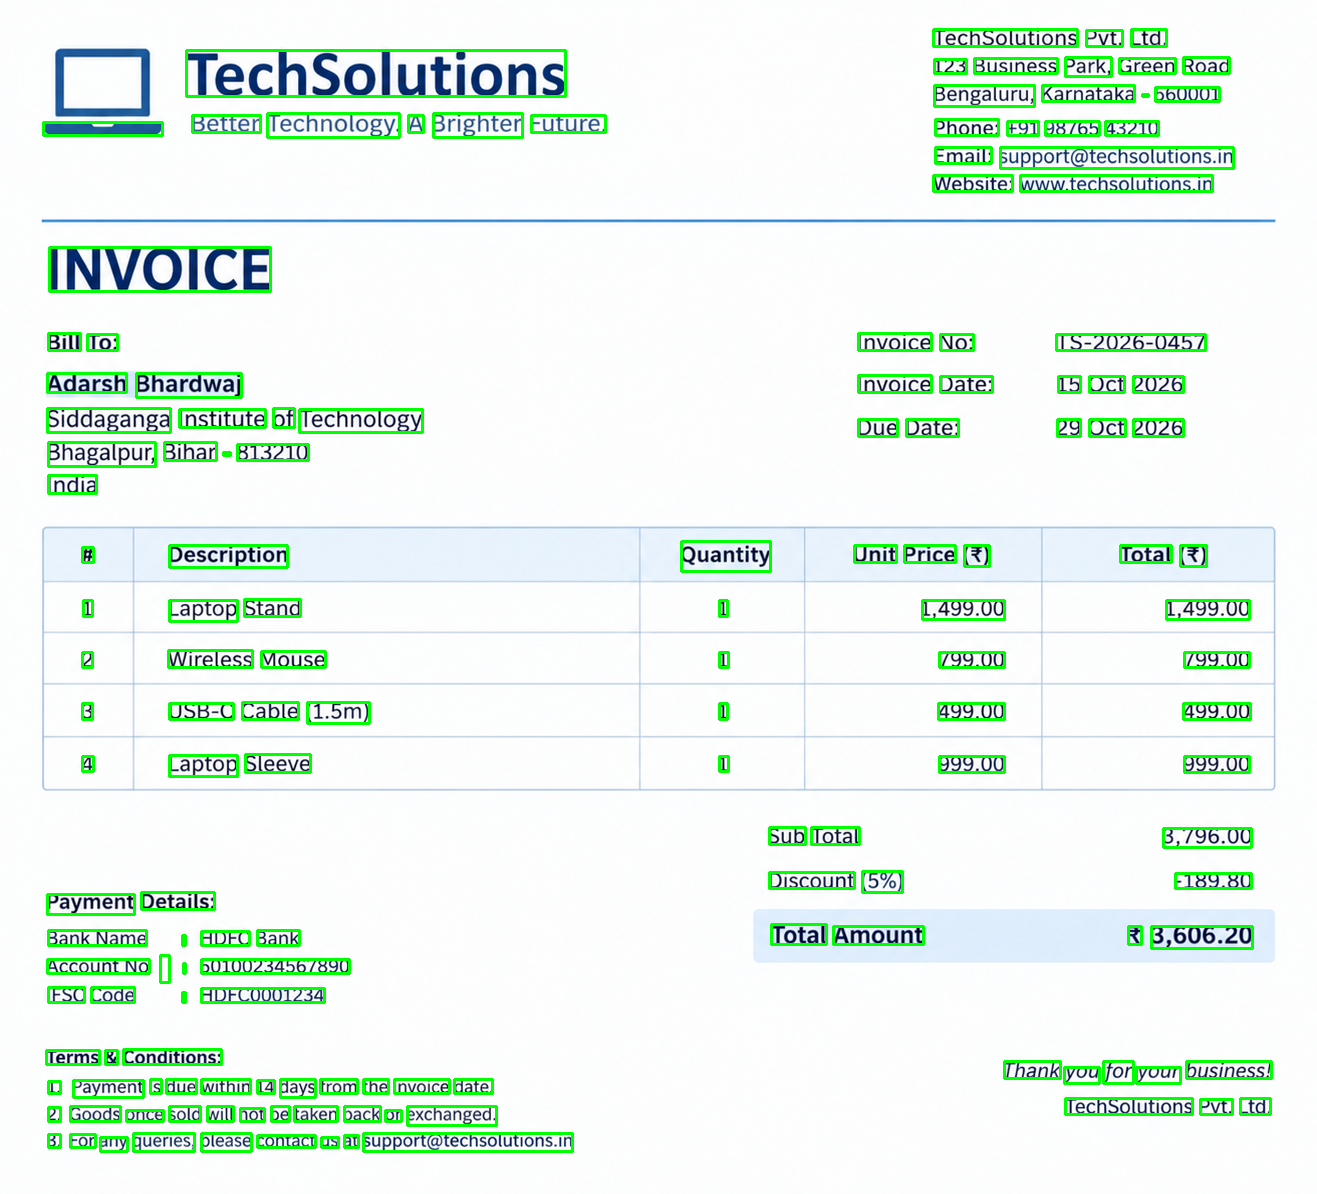

In [ ]:
from google.colab.patches import cv2_imshow

cv2_imshow(img)

In [ ]:
import cv2
img1=cv2.imread("/content/Blurred TechMart Invoice.png")

In [ ]:
text1=pytesseract.image_to_string(img1)
print(text1)
print(repr(text1))


''


In [ ]:
gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)

text_gray1 = pytesseract.image_to_string(gray)
print(repr(text_gray1))


''


In [ ]:
_, thresh1 = cv2.threshold(gray1, 127, 255, cv2.THRESH_BINARY)

Original image:


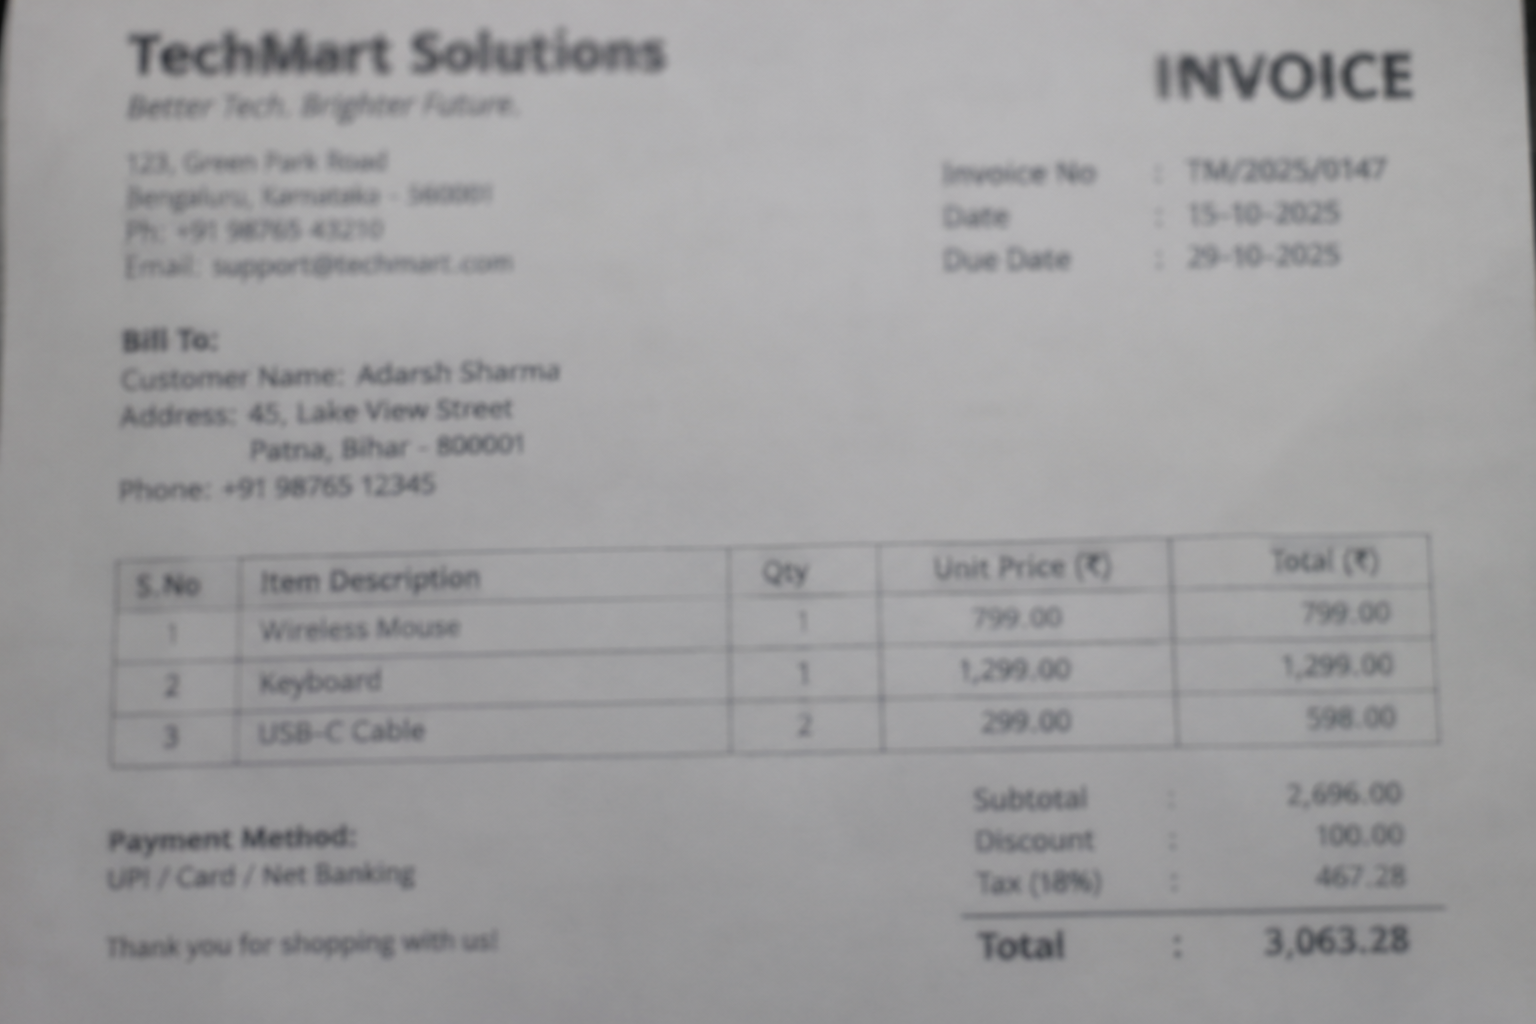

Thresholded image:


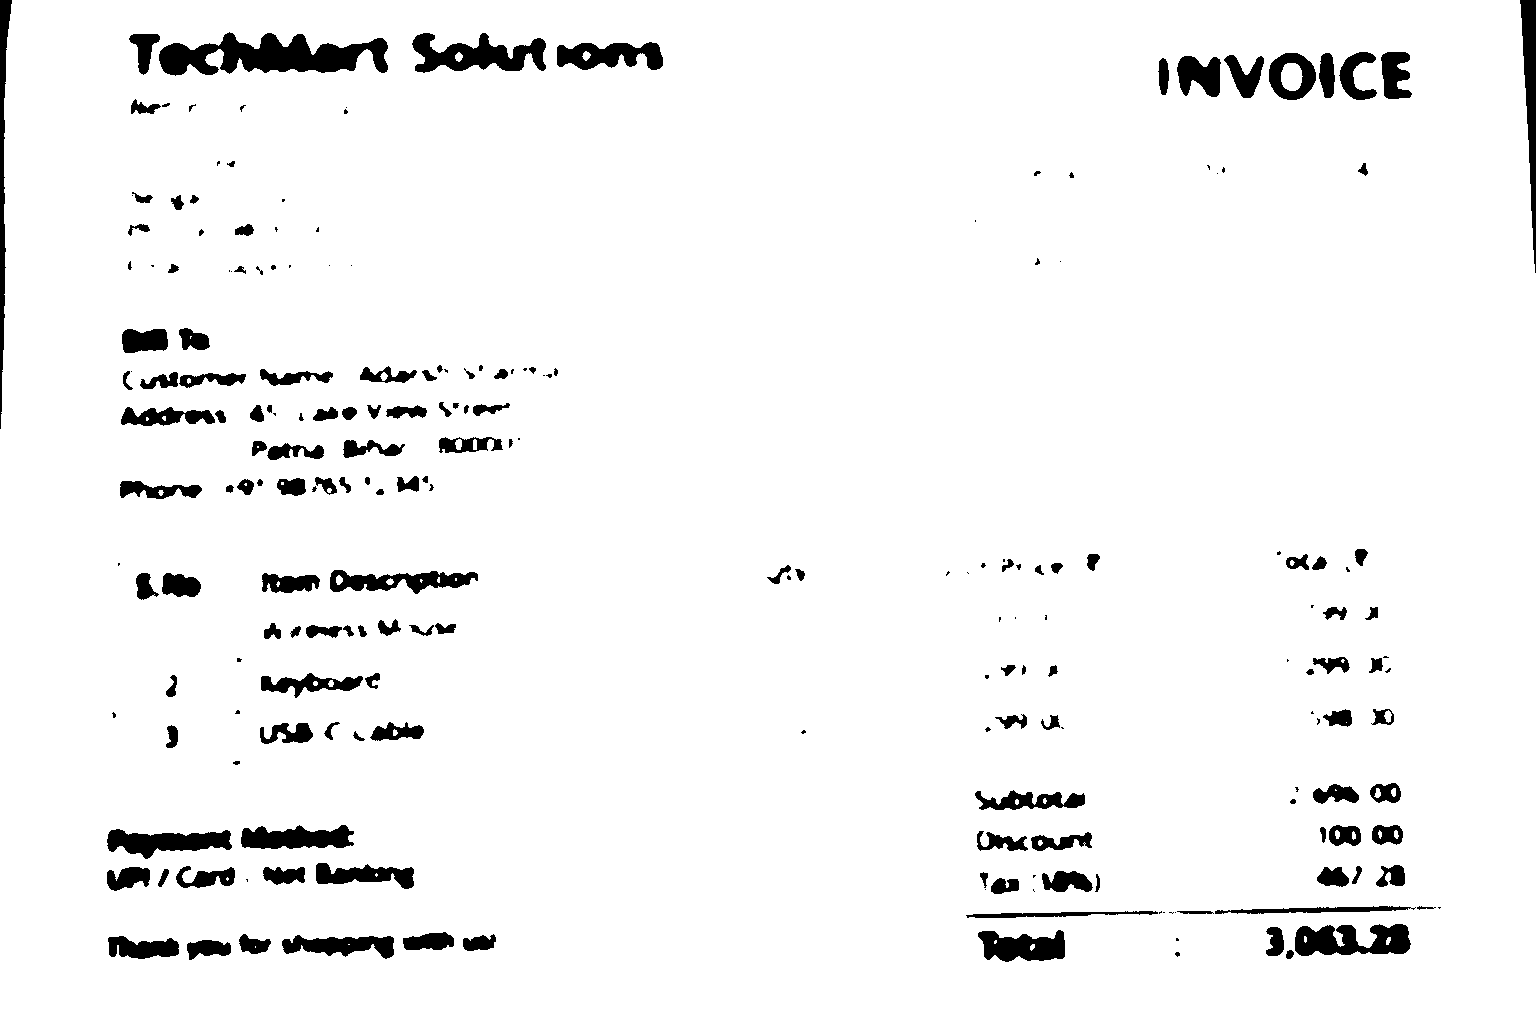

In [ ]:
from google.colab.patches import cv2_imshow

print("Original image:")
cv2_imshow(img1)

print("Thresholded image:")
cv2_imshow(thresh1)

In [ ]:
h, w = gray1.shape

resized1 = cv2.resize(
    gray1,
    (w * 2, h * 2),
    interpolation=cv2.INTER_CUBIC
)

text1 = pytesseract.image_to_string(
    resized1,
    config="--psm 6"
)
print(text1)

eg
Feet epperttectenes cor Que Date 2» © 2025
a
on =
Adarsh Sharma
comma
45, Lake View Street |
_ ' _ sg000" ,
Se en al aut
Sa ee By bia tee see
ms ' ae
oe a rs 7
on s,s : -.
. ie oe oe oe — sae . ” -
. 4 Pe aly . i?
a i. ae “3
< er as = 2
: ’ : ea ae
: 7 re Le
. " z . rae tig, er ae
CY ae ae Pe pane ee a eee P
i Te ae Pee ha eee 3 Poe 8 +a lai 7
Rs a.. "_—— a re 7
ae ar i aa ae ek ae ee ae
te ite a ae
: bo fot ett
PS t



In [ ]:
import cv2
import pytesseract

# Define the missing 'adaptive' threshold image using adaptiveThreshold
adaptive = cv2.adaptiveThreshold(
    gray1,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11,
    2
)

text_original = pytesseract.image_to_string(
    img1, config="--psm 6"
)

text_gray = pytesseract.image_to_string(
    gray1, config="--psm 6"
)

text_adaptive = pytesseract.image_to_string(
    adaptive, config="--psm 6"
)

print("ORIGINAL:\n", repr(text_original))
print("GRAYSCALE:\n", repr(text_gray))
print("ADAPTIVE THRESHOLD:\n", repr(text_adaptive))

ORIGINAL:
 're «nee we. 1S to 2025\na ies - Ove Date 29-10-2025\ntees ,\nao ther - 608001\n7 eras: oy be Price . _ kee — ,\nBes tess Mons ’ ae ‘~\napm a es pore ua a “9 a5\nSas mg\n'
GRAYSCALE:
 '’ 23 Gower Pet Nome\nCUP wens ee\nFe ees axe ge ee —\nFeet mpperanenen com a owes\npas: 45, Lake View Street |\nPatna, Bihar - $0000) |\nit ——e ue —. 2 «\n'
ADAPTIVE THRESHOLD:
 'er , r . a\nTechMart Solutions\nfester Tit, Begiies Btw, INVOICE\n: S24, Ceres bk tend , : :\nhougaiss, fartatake s BA tote No EM2025/0147 ;\n; Per St PEELS OTS Shate & Yoh 2025\nFora. tasriace Ot ertrmeet cor Due Sate —  Th10-2025\nBill To:\nCuttomnet Name: Adarsh Sharma ;\nAdiitess2 45, Lale View Strect\n| Patna, Bisar - £0000!\nPhocre: «91 98765 12345\nPs.n0_ i Mem Description oo i Gy | Unit Price (@) ~ ; “Total (t) |\nLoo F Wételess Mouee es eee 179.00 |\nBee s. ior aac ronan a Pee ASA ana OIE RE EM EEL LTT. TTT t\nope pepe oo nan 00\nfF 1 UsbC Cable ee ee ic | s9ae0 |\n. — Subtotal 2,696.00\nPayment hlethod: : ne

In [ ]:
h, w = gray1.shape

resized_gray = cv2.resize(
    gray1,
    (w * 2, h * 2),
    interpolation=cv2.INTER_CUBIC
)

adaptive_resized = cv2.adaptiveThreshold(
    resized_gray,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    31,
    11
)

text_resized = pytesseract.image_to_string(
    adaptive_resized,
    config="--psm 6"
)

print(text_resized)

t
| 7 \
pee’ . .
. 8 ENT OE
hoy ran : |
‘eu a ae eo)
‘
. ce, 7 , ,
. ,
‘ . . . . . 4
. . ,
, Cr ee .
» 46 . .
a potat : Ss



In [ ]:
# OCR Learning Roadmap

## 1. OpenCV and Image Basics
#- [x] Understanding image shape (height, width, channels)
#- [x] Understanding pixels and RGB/BGR channels
##- [x] Loading and displaying images using OpenCV
#- [x] Converting color images to grayscale
#- [x] Understanding grayscale images and channels

## 2. Image Preprocessing
#- [x] Grayscale conversion
#- [x] Thresholding
#- [x] Adaptive thresholding
#- [x] Gaussian blur (basic concept)
#- [x] Testing preprocessing techniques on blurry documents
#- [x] Comparing OCR results before and after preprocessing
#- [x] Understanding limitations of preprocessing

## 3. Tesseract OCR
#- [x] Installing and importing pytesseract
#- [x] Extracting text using image_to_string()
#- [x] Understanding OCR output
#- [x] Page Segmentation Modes (PSM 6, 7, 8)

## 4. OCR Bounding Boxes and Confidence
#- [x] Using image_to_data()
#- [x] Understanding text, left, top, width and height
#- [x] Understanding OCR confidence scores
#- [x] Looping through detected words
#- [x] Drawing bounding boxes using cv2.rectangle()
#- [x] Displaying images using cv2_imshow()

## 5. Testing OCR on Blurry Documents
#- [x] Testing OCR on a blurry invoice
#- [x] Comparing original, grayscale and adaptive thresholding
#- [x] Testing resizing and observing its limitations
#- [x] Understanding why severe blur reduces OCR accuracy
#- [x] Planning a frontend warning for blurry uploads

## 6. PDF-to-Image Conversion
#- [ ] Installing pdf2image and Poppler
#- [ ] Converting PDF pages into images
#- [ ] Understanding multipage PDF conversion
#- [ ] Displaying converted pages
#- [ ] Passing converted images to Tesseract OCR

## 7. OCR Text Cleaning
#- [ ] Removing unwanted whitespace and line breaks
#- [ ] Cleaning extracted text
#- [ ] Handling OCR recognition errors where possible

## 8. Rule-Based Field Extraction
#- [ ] Extracting email addresses using regex
#- [ ] Extracting phone numbers
#- [ ] Extracting dates
#- [ ] Extracting amounts
#- [ ] Extracting document IDs
#- [ ] Understanding limitations of regex-based extraction

## 9. OCR Evaluation and Project Integration
#- [ ] Evaluating extracted text quality
##- [ ] Integrating OCR with the document classifier
#- [ ] Connecting OCR output to field extraction
#- [ ] Handling blurry or unreadable uploads
#- [ ] Testing the complete pipeline

# Project Scope
#- CNN-based document classification
#- Tesseract-based OCR
#- Regex/rule-based field extraction
#- FastAPI backend and frontend integration
#- Human review for uncertain results

# Current Progress
#Completed: Topics 1–5
#Next: Topic 6 — PDF-to-Image Conversion

In [8]:
!pip install pdf2image
!apt-get install -y poppler-utils

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  libpoppler-dev libpoppler-private-dev libpoppler134
Recommended packages:
  poppler-data
The following NEW packages will be installed:
  poppler-utils
The following packages will be upgraded:
  libpoppler-dev libpoppler-private-dev libpoppler134
3 upgraded, 1 newly installed, 0 to remove and 47 not upgraded.
Need to get 1,532 kB of archives.
After this operation, 735 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 libpoppler-private-dev amd64 24.02.0-1ubuntu9.11 [197 kB]
Get:2 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 libpoppler-dev amd64 24.02.0-1ubuntu9.11 [5,202 B]
Get:3 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 libpoppler134 amd64 24.02.0-1ubuntu9.11 [1,118 kB]
Get:4 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 poppler-utils amd64 

In [44]:
from pdf2image import convert_from_path
page=convert_from_path("/content/OD337010058699026100.pdf")

In [45]:
print(len(page))


5


In [50]:
text = pytesseract.image_to_string(page[1])



In [47]:
print(text)


Tax Invoice
Sold By: Flipkart Internet Private Limited ,
Ship-from Address: Buildings Alyssa, Begonia & Clover, Embassy Tech Village, Outer Ring Road, Devarabeesanahalli Village,
Bengaluru, Bengaluru, Karnataka, IN - 560103, CIN: U51109KA2012PTC066107

GSTIN - 29AACCF0683K1ZD

Order ID: 0D337010058699026100 Billing Address

Order Date: 11-03-2026 Adarsh Kumar
. 357, Basaveshwara Block Hostel,
Invoice Date: 11-03-2026 Tumakuru 572102 Karnataka

Phone: xxxxxXXXXX

Description Qty Gross Discount Taxable SGST CGST Total®
Amount % value & /UTGST z
z
SAC: 998599 Offer Handling Fee 1 199.00 0.00 168.64 15.18 15.18 199.00
1, [IMEI/Serial No: T7NOCX04U60330C |
SGST/UTGST: 9.0 %
CGST: 9.0 %
SAC: 998599 Credit Card Fee 1 172.00 0.00 145.76 13.12 13.12 172.00
1, [IMEI/Serial No: T7NOCX04U60330C |
SGST/UTGST: 9.0 %
CGST: 9.0 %
Total 2 371.00 0.00 314.40 28.30 28.30 371.00
Grand Total = 371.00

Flipkart Internet Private Limited

Authorized Signatory

Flipkart
Thank You!

for shopping with us

Regd. 

In [13]:
ocr_text = "   INVOICE   \n\n\nTotal Amount:    Rs. 2500   "

clean_text = ocr_text.strip()

print(clean_text)

INVOICE   


Total Amount:    Rs. 2500


In [14]:
text = "Invoice    Number:    INV-101"

clean_text = " ".join(text.split())

print(clean_text)

Invoice Number: INV-101


In [17]:
import re

ocr_text = "Inv@oice ### Number: INV-101 !!!"

clean_text = re.sub(r"[@#!]", "", ocr_text)

print(clean_text)


Invoice  Number: INV-101 


In [25]:
import re

In [23]:
#  regrex for invoice

In [51]:
import re, json

REVIEW_THRESHOLD = 0.60
REQUIRED_FIELDS = ["invoice_number", "invoice_date", "total_amount"]


def clean_line(text):
    """Collapse whitespace but keep the line itself (line breaks matter for regex)."""
    return re.sub(r"\s+", " ", text).strip()


def result(value=None, line=None, weight=0.0, rule=None):
    if value is None:
        return {"value": None, "confidence": 0.0, "rule": None}
    ocr_conf = line["conf"] if line else 0.5
    return {"value": value, "confidence": round(ocr_conf * weight, 3), "rule": rule}


# --- invoice number ---
INV_NO_RE = re.compile(
    r"\b(?:tax\s+invoice|invoice|inv|bill|receipt)\s*(?:no|number|num|#)?\s*[.:#\-]*\s*"
    r"((?=[A-Z0-9\-/]*\d)[A-Z0-9][A-Z0-9\-/]{2,})",
    re.I,
)
INV_LABEL_ONLY_RE = re.compile(r"^(?:tax\s+)?(?:invoice|bill)\s*(?:no|number|#)?\.?\s*:?$", re.I)
TOKEN_WITH_DIGIT_RE = re.compile(r"\b(?=[A-Z0-9\-/]*\d)[A-Z0-9][A-Z0-9\-/]{2,}\b", re.I)


def extract_invoice_number(lines):
    for line in lines:
        m = INV_NO_RE.search(line["text"])
        if m:
            return result(m.group(1), line, 1.0, "label+value on same line")
    for i, line in enumerate(lines[:-1]):
        if INV_LABEL_ONLY_RE.match(line["text"]):
            m = TOKEN_WITH_DIGIT_RE.search(lines[i + 1]["text"])
            if m:
                return result(m.group(0), lines[i + 1], 0.8, "label line, value on next line")
    return result()


# --- date ---
MONTHS = r"(?:jan|feb|mar|apr|may|jun|jul|aug|sep|sept|oct|nov|dec)"
DATE_RES = [re.compile(p, re.I) for p in [
    r"\b\d{1,2}[/\-.]\d{1,2}[/\-.]\d{2,4}\b",
    r"\b\d{4}[/\-.]\d{1,2}[/\-.]\d{1,2}\b",
    rf"\b\d{{1,2}}[\s\-]*{MONTHS}[a-z]*\.?,?[\s\-]*\d{{2,4}}\b",
    rf"\b{MONTHS}[a-z]*\.?\s+\d{{1,2}},?\s+\d{{2,4}}\b",
]]


def find_date(text):
    for rx in DATE_RES:
        m = rx.search(text)
        if m:
            return m.group(0)
    return None


def extract_date(lines):
    passes = [
        (("invoice date", "bill date", "date of issue", "issue date", "dated"), 1.0, "specific date label"),
        (("date",), 0.8, "generic 'date' label"),
    ]
    for keywords, weight, rule in passes:
        for line in lines:
            low = line["text"].lower()
            if "due" in low:
                continue
            if any(k in low for k in keywords):
                d = find_date(line["text"])
                if d:
                    return result(d, line, weight, rule)
    for line in lines:
        if "due" in line["text"].lower():
            continue
        d = find_date(line["text"])
        if d:
            return result(d, line, 0.5, "first date found in document")
    return result()


# --- total amount ---
TOTAL_KEYWORDS = [
    ("grand total", 1.0), ("amount due", 1.0), ("balance due", 1.0),
    ("net payable", 1.0), ("total amount", 0.9), ("total", 0.7),
]
TOTAL_EXCLUDE = ("subtotal", "sub total", "sub-total", "tax", "gst", "cgst",
                 "sgst", "igst", "vat", "discount")
AMOUNT_RE = re.compile(r"(?<![\d/\-.])(\d{1,3}(?:,\d{2,3})+(?:\.\d{1,2})?|\d+\.\d{1,2}|\d{2,})(?![\d/\-])")


def to_float(s):
    return float(s.replace(",", ""))


def last_amount(text):
    found = AMOUNT_RE.findall(text)
    return found[-1] if found else None


def extract_total(lines):
    for keyword, weight in TOTAL_KEYWORDS:
        hits = []
        for i, line in enumerate(lines):
            low = line["text"].lower()
            if keyword not in low or any(x in low for x in TOTAL_EXCLUDE):
                continue
            amount = last_amount(line["text"])
            src = line
            if amount is None and i + 1 < len(lines):
                amount = last_amount(lines[i + 1]["text"])
                src = lines[i + 1]
            if amount:
                hits.append((amount, src))
        if hits:
            # several "total ..." lines can exist (shipping total, item total...):
            # the real total is the largest one
            amount, src = max(hits, key=lambda h: to_float(h[0]))
            return result(f"{to_float(amount):.2f}", src, weight, f"keyword '{keyword}' (largest match)")
    return result()


# --- vendor + GSTIN ---
VENDOR_SKIP_RE = re.compile(r"invoice|bill to|ship to|gstin|date|tel|phone|mobile|@|www|original|copy", re.I)
COMPANY_RE = re.compile(
    r"\b(?:pvt\.?|private|ltd\.?|limited|llp|inc\.?|corp\.?|co\.|traders|enterprises|"
    r"industries|solutions|technologies|stores?|labs?)\b", re.I)
LABEL_ONLY_RE = re.compile(
    r"^(?:tax\s+invoice|invoice|seller|supplier|sold by|from|bill(?:ed)? to|"
    r"ship(?:ped)? (?:to|from)|original(?: for recipient)?|duplicate|copy)\s*:?$", re.I)


def extract_vendor(lines):
    top = lines[:12]
    usable = [l for l in top
              if not LABEL_ONLY_RE.match(l["text"]) and not VENDOR_SKIP_RE.search(l["text"])]
    for line in usable:
        if COMPANY_RE.search(line["text"]):
            return result(line["text"], line, 0.8, "company-name line near top")
    for line in usable:
        text = line["text"]
        letters = sum(c.isalpha() for c in text)
        if len(text) >= 3 and letters / len(text) >= 0.6:
            return result(text, line, 0.6, "first clean line near top")
    return result()


GSTIN_RE = re.compile(r"\b\d{2}[A-Z]{5}\d{4}[A-Z][1-9A-Z]Z[0-9A-Z]\b")


def extract_gstin(lines):
    for line in lines:
        m = GSTIN_RE.search(line["text"].upper())
        if m:
            return result(m.group(0), line, 1.0, "GSTIN format match")
    return result()


# --- put it together ---
def extract_invoice_fields(lines):
    fields = {
        "invoice_number": extract_invoice_number(lines),
        "invoice_date": extract_date(lines),
        "total_amount": extract_total(lines),
        "vendor_name": extract_vendor(lines),
        "gstin": extract_gstin(lines),
    }
    reasons = []
    for name in REQUIRED_FIELDS:
        f = fields[name]
        if f["value"] is None:
            reasons.append(f"{name}: not found")
        elif f["confidence"] < REVIEW_THRESHOLD:
            reasons.append(f"{name}: low confidence ({f['confidence']})")
    return {"fields": fields, "needs_review": bool(reasons), "review_reasons": reasons}

In [52]:
lines = [{"text": clean_line(t), "conf": 1.0, "top": i, "left": 0}
         for i, t in enumerate(text.splitlines()) if t.strip()]

out = extract_invoice_fields(lines)

for name, f in out["fields"].items():
    print(f"{name:15s} -> {f['value']}   (confidence {f['confidence']}, rule: {f['rule']})")
print("\nNeeds review:", out["needs_review"])
for r in out["review_reasons"]:
    print("  -", r)

invoice_number  -> None   (confidence 0.0, rule: None)
invoice_date    -> 11-03-2026   (confidence 1.0, rule: specific date label)
total_amount    -> 156.00   (confidence 1.0, rule: keyword 'grand total' (largest match))
vendor_name     -> Sold By: Damson Technologies Pvt. Ltd. ,   (confidence 0.8, rule: company-name line near top)
gstin           -> 36AABCD3982G1ZM   (confidence 1.0, rule: GSTIN format match)

Needs review: True
  - invoice_number: not found
